# Iris: Decision Tree and Random Forest (local CSV)

This notebook loads the local **`iris.csv`** file and trains two tree-based classifiers:

1. Decision Tree
2. Random Forest

**About the CSV format:** the first line is a metadata header (`150,4,setosa,versicolor,virginica` =
number of samples, number of features, class names). The real data starts on line 2 and the label is an integer (0, 1, 2).
So we skip the first row and assign column names ourselves.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/test/

Mounted at /content/drive
/content/drive/MyDrive/test


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Fixed seed so that results are reproducible
SEED = 42

# 1. Load the Data

In [3]:
csv_path = "/content/drive/MyDrive/test/iris.csv"   # change this if the file is in another folder

feature_names = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
class_names = ['setosa', 'versicolor', 'virginica']   # taken from the CSV's first line

# skiprows=1 skips the metadata line; header=None because there is no real header row
df = pd.read_csv(csv_path, skiprows=1, header=None, names=feature_names + ['label'])

print(df.shape)
print(df.head())
print()
# Number of samples per class (should be 50 each)
print(df['label'].value_counts().sort_index())

(150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   label  
0      0  
1      0  
2      0  
3      0  
4      0  

label
0    50
1    50
2    50
Name: count, dtype: int64


# 2. Train / Test Split

We hold out 30% of the data for testing. `stratify=y` keeps the class proportions the same in both sets.

In [4]:
X = df[feature_names].values   # features, shape (150, 4)
y = df['label'].values         # integer labels 0/1/2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (105, 4)  Test: (45, 4)


# 3. Decision Tree

A decision tree repeatedly splits the data using a threshold on one feature, choosing the split that
best separates the classes (here measured with Gini impurity).

In [5]:
# Train a decision tree (default settings: grows until the leaves are pure)
tree = DecisionTreeClassifier(random_state=SEED)
tree.fit(X_train, y_train)

# Evaluate on training and test data
print("Train accuracy:", accuracy_score(y_train, tree.predict(X_train)))
print("Test accuracy :", accuracy_score(y_test, tree.predict(X_test)))
print("Tree depth    :", tree.get_depth(), " Leaves:", tree.get_n_leaves())

Train accuracy: 1.0
Test accuracy : 0.9333333333333333
Tree depth    : 5  Leaves: 8


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



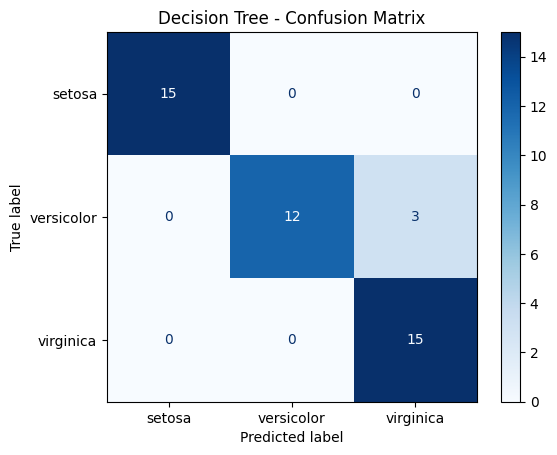

In [6]:
# Detailed test-set report
y_pred = tree.predict(X_test)
print(classification_report(y_test, y_pred, target_names=class_names))

# Confusion matrix: rows = true class, columns = predicted class
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=class_names).plot(cmap='Blues')
plt.title("Decision Tree - Confusion Matrix")
plt.show()

## 3.1 Visualize the Tree

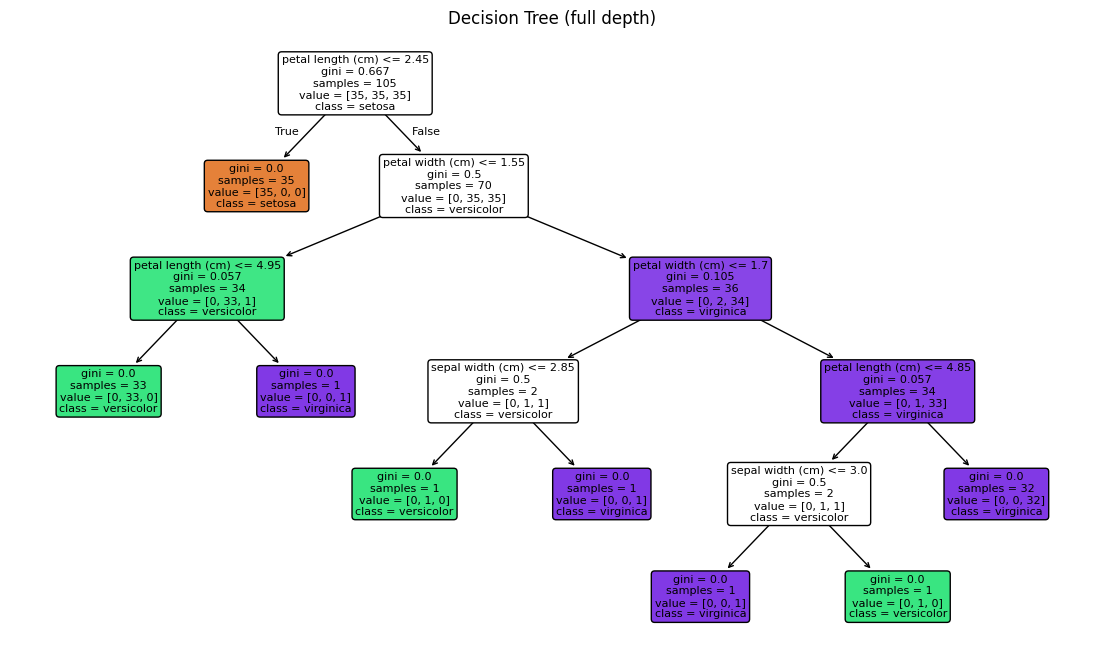

In [7]:
# Draw the tree: each node shows the split rule, Gini impurity, sample count and class distribution
plt.figure(figsize=(14, 8))
plot_tree(tree, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (full depth)")
plt.show()

In [8]:
# The same tree as plain text (shorter version: depth limited to 3 for readability)
small_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
print(export_text(small_tree, feature_names=feature_names))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- class: 2



## 3.2 Overfitting and `max_depth`

A tree that is allowed to grow very deep can memorize the training data. Limiting `max_depth` is a simple way to control this.
We compare training and test accuracy for different depths.

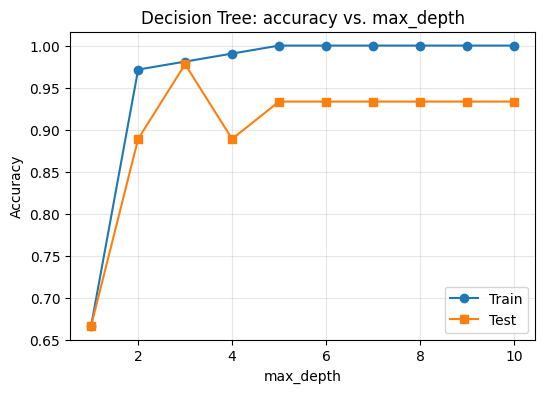

In [9]:
depths = range(1, 11)
train_scores, test_scores = [], []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train)
    train_scores.append(m.score(X_train, y_train))
    test_scores.append(m.score(X_test, y_test))

plt.figure(figsize=(6, 4))
plt.plot(depths, train_scores, marker='o', label='Train')
plt.plot(depths, test_scores, marker='s', label='Test')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: accuracy vs. max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3.3 Feature Importance

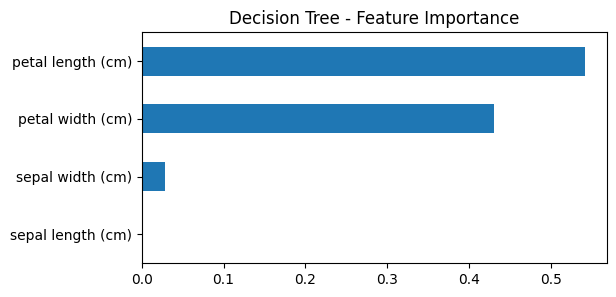

In [10]:
# Importance = how much each feature reduces impurity, summed over all splits (sums to 1)
imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
imp.plot(kind='barh', figsize=(6, 3), title="Decision Tree - Feature Importance")
plt.show()

# 4. Random Forest

A random forest trains many decision trees, each on a random bootstrap sample of the data and
a random subset of features at each split, then combines them by majority vote.
This reduces the overfitting of a single tree.

In [11]:
# 200 trees; oob_score=True also gives an "out-of-bag" accuracy estimate
# (each tree is tested on the samples it did not see during training)
rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=SEED)
rf.fit(X_train, y_train)

print("Train accuracy:", accuracy_score(y_train, rf.predict(X_train)))
print("Test accuracy :", accuracy_score(y_test, rf.predict(X_test)))
print("OOB score     :", rf.oob_score_)

Train accuracy: 1.0
Test accuracy : 0.9111111111111111
OOB score     : 0.9523809523809523


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



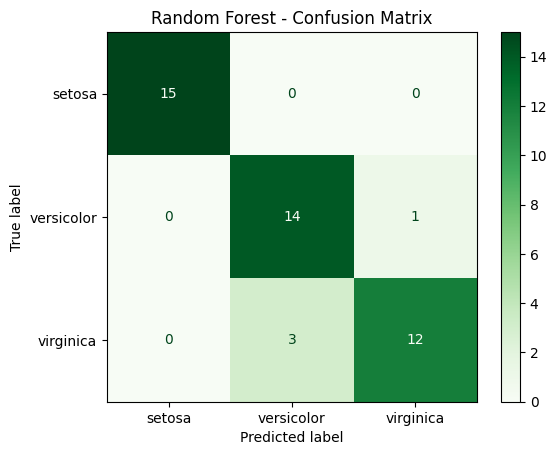

In [12]:
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=class_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=class_names).plot(cmap='Greens')
plt.title("Random Forest - Confusion Matrix")
plt.show()

## 4.1 Feature Importance

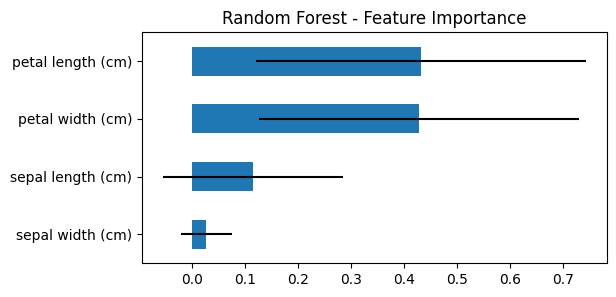

petal length (cm)    0.430948
petal width (cm)     0.427143
sepal length (cm)    0.114955
sepal width (cm)     0.026953
dtype: float64


In [13]:
# Importance averaged over all trees; the std shows how much it varies between trees
importances = pd.Series(rf.feature_importances_, index=feature_names)
std = np.std([t.feature_importances_ for t in rf.estimators_], axis=0)

importances.sort_values().plot(kind='barh', xerr=pd.Series(std, index=feature_names)[importances.sort_values().index],
                               figsize=(6, 3), title="Random Forest - Feature Importance")
plt.show()
print(importances.sort_values(ascending=False))

## 4.2 Effect of the Number of Trees

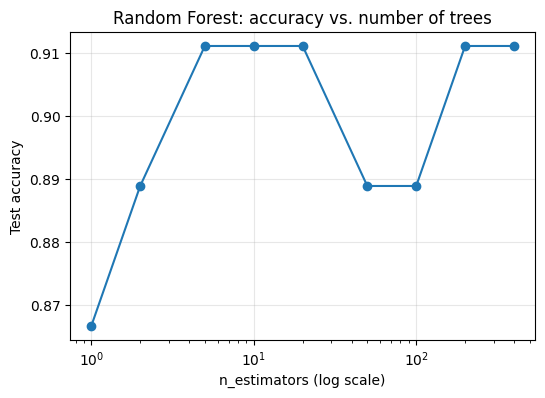

In [14]:
# More trees usually make the result more stable; gains flatten out after a while
n_list = [1, 2, 5, 10, 20, 50, 100, 200, 400]
scores = []
for n in n_list:
    m = RandomForestClassifier(n_estimators=n, random_state=SEED).fit(X_train, y_train)
    scores.append(m.score(X_test, y_test))

plt.figure(figsize=(6, 4))
plt.plot(n_list, scores, marker='o')
plt.xscale('log')
plt.xlabel("n_estimators (log scale)")
plt.ylabel("Test accuracy")
plt.title("Random Forest: accuracy vs. number of trees")
plt.grid(alpha=0.3)
plt.show()

# 5. Compare the Two Models with Cross Validation

A single train/test split on only 150 rows is noisy. 10-fold stratified cross validation on the whole dataset
gives a more reliable comparison.

Decision Tree (max_depth=3): mean=0.9400  std=0.0554
Decision Tree (full depth): mean=0.9333  std=0.0516
Random Forest (200 trees): mean=0.9533  std=0.0521


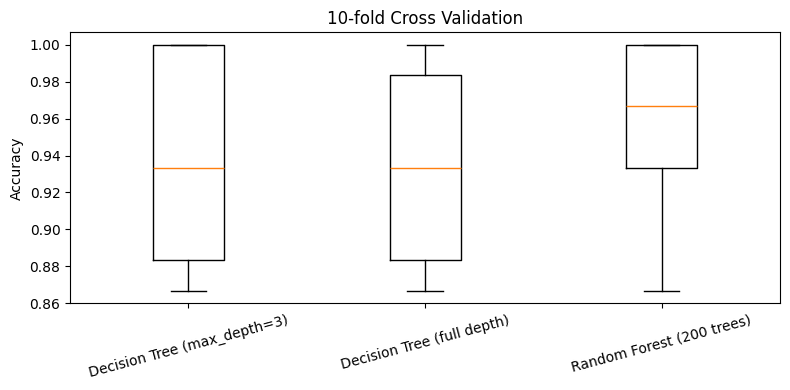

In [15]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

models = {
    "Decision Tree (max_depth=3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Decision Tree (full depth)":  DecisionTreeClassifier(random_state=SEED),
    "Random Forest (200 trees)":   RandomForestClassifier(n_estimators=200, random_state=SEED),
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name}: mean={scores.mean():.4f}  std={scores.std():.4f}")

# Box plot of the 10 fold scores for each model
plt.figure(figsize=(8, 4))
plt.boxplot(list(cv_results.values()))
plt.xticks(range(1, len(cv_results) + 1), list(cv_results.keys()), rotation=15)
plt.ylabel("Accuracy")
plt.title("10-fold Cross Validation")
plt.tight_layout()
plt.show()

# 6. Hyperparameter Tuning (Grid Search)

`GridSearchCV` tries every combination of the listed parameters using cross validation on the training set.

In [16]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 2, 3, 5],
    "min_samples_leaf": [1, 2, 4],
}

grid = GridSearchCV(RandomForestClassifier(random_state=SEED), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))
print("Test accuracy   :", round(grid.best_estimator_.score(X_test, y_test), 4))

Best parameters : {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 100}
Best CV accuracy: 0.9619
Test accuracy   : 0.9111


# 7. Decision Boundaries (2 features)

To draw boundaries in 2D, we retrain the models using only the two petal features
(petal length and petal width), which are the most informative ones.

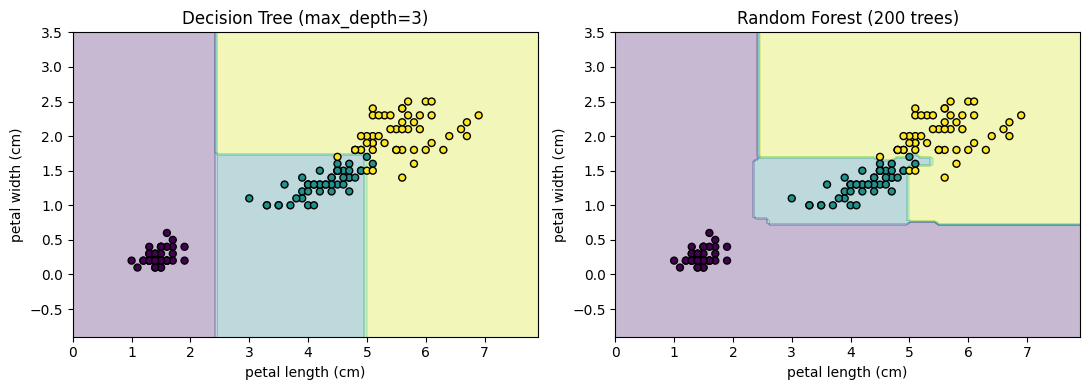

In [17]:
from sklearn.inspection import DecisionBoundaryDisplay

# Use only petal length (index 2) and petal width (index 3)
X2 = X[:, 2:4]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, model) in zip(axes, [
    ("Decision Tree (max_depth=3)", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ("Random Forest (200 trees)",   RandomForestClassifier(n_estimators=200, random_state=SEED)),
]):
    model.fit(X2, y)
    # Color the background by predicted class
    DecisionBoundaryDisplay.from_estimator(model, X2, ax=ax, response_method="predict", alpha=0.3,
                                           xlabel=feature_names[2], ylabel=feature_names[3])
    # Overlay the actual samples
    ax.scatter(X2[:, 0], X2[:, 1], c=y, edgecolor='k', s=25)
    ax.set_title(title)
plt.tight_layout()
plt.show()

# 8. Predict a New Sample

In [18]:
# A new flower: sepal length, sepal width, petal length, petal width (cm)
new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=feature_names)

pred = rf.predict(new_flower.values)[0]
proba = rf.predict_proba(new_flower.values)[0]

print("Predicted class:", class_names[pred])
for name, p in zip(class_names, proba):
    print(f"  P({name}) = {p:.3f}")

Predicted class: virginica
  P(setosa) = 0.000
  P(versicolor) = 0.060
  P(virginica) = 0.940


## Summary

* A single decision tree is easy to interpret (you can read the rules), but a fully grown tree can overfit.
* A random forest is usually more stable, at the cost of interpretability. In 10-fold cross validation it scored slightly higher than a single tree,
  but on the one 70/30 split the single tree happened to score higher, which shows how noisy a single small test set is.
* On Iris the differences are small because the dataset is easy; petal length and petal width are by far the most important features.